# Molecular Descriptors Calculation and Model Developments

In [1]:
#@title Installing the required packages
!pip install numpy rdkit pandas matplotlib scikit-learn eli5

In [2]:
#@title File I/O configuration

import os

#Modify the path to indicate the folder where all files will be stored,
#and uncomment the following line if you have uploaded your file directly
PATH = "/content/"

#If you are using Google Drive, uncomment the following lines:
from google.colab import drive
drive.mount('/content/drive')
PATH = "/content/drive/your_folder/"

Mounted at /content/drive


In [3]:
import pandas as pd
import os

file_path = '/content/drive/MyDrive/QSAR_Models/RAT_LC50_sanitized.csv'

if os.path.exists(file_path):
    try:
        # Let's try to read with ';' delimiter as typically used in this notebook, otherwise fall back
        df = pd.read_csv(file_path, sep=';')
    except Exception:
        df = pd.read_csv(file_path)
    print(f"Successfully loaded the dataset. Shape: {df.shape}")
    display(df.head())
else:
    print(f"File not found at: {file_path}. Please verify the folder structure in your Drive.")

Successfully loaded the dataset. Shape: (136, 2)


,SMILES,y
0,FC(F)(F)Br,8.751
1,OCC(F)(F)F,6.672
2,FC(F)(Cl)C(F)(Cl)Cl,8.313
3,FC(F)(Cl)C(F)(F)Cl,9.625
4,FC(F)(F)C(F)(F)Cl,7.500


In [4]:
#@title Uploading initial file
## Running this cell is necessary to open the upload dialogue. Then, use it to upload the initial .csv file
##(probably called "RAT_LC50_sanitized.csv").
#from google.colab import files
#uploaded = files.upload()

## Part 2. Calculation of molecular descriptors

### Importing libraries and preparing the dataset

First, we need to import all the required modules and libraries.

To perform the following steps, we will need:
- `pandas`
- `numpy`
- the `Chem` module from `rdkit`
- the `rdMolDescriptors` and `Descriptors` modules from `rdkit.Chem`

In [5]:
#@title Import the necessary libraries
import pandas as pd
import numpy as np
from rdkit import Chem
from rdkit.Chem import rdMolDescriptors, Descriptors

Then, import the sanitised RAT_LC50 dataset (`RAT_LC50_sanitized.csv`) and save the SMILES column as a list.

In [6]:
#@title Load the dataset and store the SMILES
import pandas as pd

# Path to the sanitized dataset
file_path = '/content/drive/MyDrive/QSAR_Models/RAT_LC50_sanitized.csv'

# Load the dataset using correct delimiter ';'
df_sanitized = pd.read_csv(file_path, sep=';')

# Save the SMILES column as a list
smiles_list = df_sanitized['SMILES'].tolist()

print(f"Loaded {len(smiles_list)} SMILES successfully.")

Loaded 136 SMILES successfully.


### Calculating descriptors  

Now, as we did for the classification problem, we will calculate molecular descriptors using RDKit and Mordred. Since descriptor calculation is used to represent molecular structure and is not directly related to the endpoint, the code is exactly the same as that used in Module 2.

However, in this lesson, we will skip the first exercises involving the manual calculation of some descriptors, such as molecular weight and the number of hydrogen atoms, which were completed in Section 2 ([link](https://colab.research.google.com/drive/12OZsDcl9lNgd7vRE6YHSeMrRJn4Wq9hD#scrollTo=386589e5)). This is not an issue, since these descriptors are included among those calculated with RDKit.

In [7]:
#@title Compute the RDKit descriptors
# Create a list to store the descriptors
descs_list = []
valid_indices = []

# Iterate over the SMILES, compute the descriptors, and append them to the list
# We will use all available descriptor calculators from RDKit Descriptors
calc_list = [desc[0] for desc in Descriptors._descList]

for idx, smiles in enumerate(smiles_list):
    mol = Chem.MolFromSmiles(smiles)
    if mol is not None:
        mol_descs = {}
        # Add identifier columns
        mol_descs['SMILES'] = smiles
        mol_descs['y'] = df_sanitized.iloc[idx]['y']
        # Compute each descriptor
        for desc_name in calc_list:
            func = getattr(Descriptors, desc_name)
            try:
                mol_descs[desc_name] = func(mol)
            except Exception:
                mol_descs[desc_name] = np.nan
        descs_list.append(mol_descs)

# Convert the list of descriptors into a DataFrame
df_regression_with_descriptors = pd.DataFrame(descs_list)

# Keep this to check the resulting DataFrame
print(f"Computed descriptors shape: {df_regression_with_descriptors.shape}")
display(df_regression_with_descriptors.head())

Computed descriptors shape: (136, 219)


,SMILES,y,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,HeavyAtomMolWt,...,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea
0,FC(F)(F)Br,8.751,10.270833,10.270833,1.375000,-4.187500,0.461011,12.00,148.909,148.909,...,0,0,0,0,0,0,0,0,0,0
1,OCC(F)(F)F,6.672,10.534722,10.534722,1.729167,-4.402778,0.470675,12.00,100.039,97.015,...,0,0,0,0,0,0,0,0,0,0
2,FC(F)(Cl)C(F)(Cl)Cl,8.313,11.544753,11.544753,3.685957,-4.226080,0.553756,14.25,187.375,187.375,...,0,0,0,0,0,0,0,0,0,0
3,FC(F)(Cl)C(F)(F)Cl,9.625,11.112654,11.112654,3.793981,-4.658179,0.419713,14.25,170.920,170.920,...,0,0,0,0,0,0,0,0,0,0
4,FC(F)(F)C(F)(F)Cl,7.500,10.869599,10.869599,3.550926,-5.630401,0.371228,14.25,154.465,154.465,...,0,0,0,0,0,0,0,0,0,0


In [8]:
#@title Save the resulting DataFrame
# Set the path to save the generated descriptors file
save_path = os.path.join('/content/drive/MyDrive/QSAR_Models/', 'RAT_LC50_descriptors.csv')

# Save the dataframe using ';' as the delimiter and without saving the index
df_regression_with_descriptors.to_csv(save_path, sep=';', index=False)
print(f"DataFrame saved successfully to {save_path}")

DataFrame saved successfully to /content/drive/MyDrive/QSAR_Models/RAT_LC50_descriptors.csv


### Initial cleaning of descriptors for the RAT LC₅₀ inhalation database

The next cell is used only to load the most recently generated `.csv` file, so that if any mistakes are made when processing the DataFrame in the following cells, you can load it again.

In [9]:
#@title Reload the generated descriptors dataset
# Ensure we point to the correct directory where we saved the CSV
PATH = '/content/drive/MyDrive/QSAR_Models/'
df_regression_with_descriptors = pd.read_csv(PATH + 'RAT_LC50_descriptors.csv', sep=';')
print(f"Loaded dataset with shape: {df_regression_with_descriptors.shape}")

Loaded dataset with shape: (136, 219)


### **Q1.** How many descriptors are there in the initial DataFrame?

In [10]:
#@title Count the descriptors
# The number of descriptor columns is the total number of columns minus the identifiers ('SMILES' and 'y')
num_descriptors = df_regression_with_descriptors.shape[1] - 2
print(f"There are {num_descriptors} molecular descriptors in the initial DataFrame.")

There are 217 molecular descriptors in the initial DataFrame.


As in the classification problem, we will process this DataFrame in order to:

*   eliminate descriptor values that are strings, replacing them with a non-numeric value (`np.nan`)
*   eliminate values that are too large or too small, including infinite values, replacing them with a non-numeric value (`np.nan`)
*   filter out columns with a high number of missing values, i.e. more than 15%

To do so, we first define the columns that contain descriptors and apply the transformation to these columns.

In [11]:
#@title Descriptor cleaning
# 1. Extract a list with the names of the descriptor columns (excluding 'SMILES' and 'y')
descriptor_cols = [col for col in df_regression_with_descriptors.columns if col not in ['SMILES', 'y']]

# 2. Create a copy and clean descriptor columns: replace alphabetical-only/non-numeric strings with np.nan
df_cleaned_descs = df_regression_with_descriptors.copy()
for col in descriptor_cols:
    # Coerce errors to NaN, which handles alphabetical strings and non-numeric entries
    df_cleaned_descs[col] = pd.to_numeric(df_cleaned_descs[col], errors='coerce')

# 3. Ensure all descriptor values are cast to float64
df_cleaned_descs[descriptor_cols] = df_cleaned_descs[descriptor_cols].astype(np.float64)

# 4. Convert both positive and negative infinities to np.nan
df_cleaned_descs[descriptor_cols] = df_cleaned_descs[descriptor_cols].replace([np.inf, -np.inf], np.nan)

# 5. Eliminate columns where all values are np.nan
df_cleaned_descs.dropna(axis=1, how='all', inplace=True)

# Update our descriptor list after removing all-NaN columns
remaining_cols = [col for col in df_cleaned_descs.columns if col not in ['SMILES', 'y']]

# 6. Eliminate columns with more than 15% np.nan values
missing_ratios = df_cleaned_descs[remaining_cols].isnull().mean()
cols_to_drop = missing_ratios[missing_ratios > 0.15].index.tolist()
df_cleaned_descs.drop(columns=cols_to_drop, inplace=True)

print(f"Initial cleaning done. Remaining columns: {df_cleaned_descs.shape[1]}")

Initial cleaning done. Remaining columns: 219


### **Q2.** How many descriptors are there after the initial descriptor cleaning?


In [12]:
#@title Count the descriptors after initial cleaning
# The number of descriptor columns is the total number of columns minus the identifiers ('SMILES' and 'y')
num_descriptors_cleaned = df_cleaned_descs.shape[1] - 2
print(f"There are {num_descriptors_cleaned} molecular descriptors after the initial cleaning.")

There are 217 molecular descriptors after the initial cleaning.


Now, save the cleaned DataFrame as `RAT_LC50_descriptors_cleaned.csv`.

In [13]:
#@title Save the resulting DataFrame
save_path_cleaned = os.path.join('/content/drive/MyDrive/QSAR_Models/', 'RAT_LC50_descriptors_cleaned.csv')
df_cleaned_descs.to_csv(save_path_cleaned, sep=';', index=False)
print(f"Cleaned DataFrame saved successfully to {save_path_cleaned}")

Cleaned DataFrame saved successfully to /content/drive/MyDrive/QSAR_Models/RAT_LC50_descriptors_cleaned.csv


## Part 3: Train/test splitting and standardisation

### Train/test splitting

The next cell is used only to load the most recently generated `.csv` file, so that if any mistakes are made when processing the DataFrame in the following cells, you can load it again.

In [14]:
df_regression_with_descriptors = pd.read_csv(PATH + "RAT_LC50_descriptors_cleaned.csv", sep=';')

In order to use our data to build a machine learning model, we need to obtain a training set and a test set. To do this, we need a DataFrame containing the SMILES column, the output variable (`y`) column, and the transformed features, such as the one generated in the previous section.

The simplest approach is to split the data randomly. Use the random_state seed defined in the next cell to ensure the reproducibility of the results. We will allocate 70% of the data to the training set and 30% to the test set.

Check the relevant [scikit-learn documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html) and save the training and test datasets in the predefined variables.

Then, save the DataFrames into two .csv files:
- `RAT_LC50_Train.csv`
- `RAT_LC50_Test.csv`  


These steps are also the same as in the classification problem. In this case, we will use 2027 as the seed for the random components. Note that this has no particular meaning or function; it was simply an arbitrary choice.

In [15]:
#@title Create and save the training and test DataFrames
SEED = 2027
test_s = 0.3
from sklearn.model_selection import train_test_split

df_train, df_test = train_test_split(df_cleaned_descs, test_size=test_s, random_state=SEED)

df_train.to_csv(PATH + 'RAT_LC50_Train.csv', sep=';', index=False)
df_test.to_csv(PATH + 'RAT_LC50_Test.csv', sep=';', index=False)
print(f"Data successfully split and saved. Training set shape: {df_train.shape}, Test set shape: {df_test.shape}")

Data successfully split and saved. Training set shape: (95, 219), Test set shape: (41, 219)


### Imputation of the descriptor matrix

The next cell is used only to load the most recently generated `.csv` files, so that if any mistakes are made when processing the DataFrames in the following cells, you can load them again.

In [16]:
df_train = pd.read_csv(PATH + "RAT_LC50_Train.csv", sep=';')
df_test = pd.read_csv(PATH + "RAT_LC50_Test.csv", sep=';')

The machine learning algorithms that we use in QSAR are designed to use numerical descriptors to describe chemical structure. Therefore, we need to ensure that all descriptor values are numerical and have sensible values.

To do this, we will perform a process called imputation, which consists of identifying null values and replacing them with the average of the values for the three most similar molecules in the training dataset that have a valid value for that descriptor.

In the following cell, you have a function that performs the imputation and a few preparatory steps. This function:

- requires two inputs: the table of descriptors to be imputed and the table of descriptors from the training set, which is used to find similar molecules
- selects only the descriptor columns
- converts all values to the same numeric type (`float64`)
- instantiates a `KNNImputer` object with the appropriate parameters (You can check the [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.impute.KNNImputer.html))
- fits the KNNImputer using the `training` data  
- transforms the invalid values in the target dataset
- returns only the transformed dataset

This step is also the same as in the classification problem.  

In [17]:
#@title Create a function for data imputation
from sklearn.impute import KNNImputer
import numpy as np
import pandas as pd

def imputation_prediction(target_df, train_df, desc_columns):
    ''' Function to perform the imputation in a dataframe of descriptors,
        requires two datasets: the one to be imputated and the one used to inform the imputation (it can be the same)'''
    imputer = KNNImputer(n_neighbors=3, weights='uniform', missing_values=np.nan)
    imputer.fit(train_df[desc_columns])
    imputed_matrix = imputer.transform(target_df[desc_columns])
    imputed_desc_df = pd.DataFrame(imputed_matrix, columns=desc_columns, index=target_df.index)
    imputed_df = pd.concat([target_df[['SMILES', 'y']], imputed_desc_df], axis=1)
    return imputed_df

Apply the function above to the training and test sets obtained from the split.

Then, save the imputed DataFrames as `.csv` files.

**Note:** Remember to use `;` as the `.csv` delimiter and to exclude the DataFrame index from the new `.csv` files.

In [18]:
#@title Apply the imputation function to the training and test DataFrames
# Extract the descriptor column names and store them in a list
desc_columns = [col for col in df_train.columns if col not in ['SMILES', 'y']]

# Apply the imputation_prediction function
df_train_imputed = imputation_prediction(df_train, df_train, desc_columns)
df_test_imputed = imputation_prediction(df_test, df_train, desc_columns)

# Save the imputed DataFrames
df_train_imputed.to_csv(PATH + 'RAT_LC50_Train_imputed.csv', sep=';', index=False)
df_test_imputed.to_csv(PATH + 'RAT_LC50_Test_imputed.csv', sep=';', index=False)
print("Imputation completed and datasets saved successfully!")

Imputation completed and datasets saved successfully!


### Scaling the descriptor matrix

The next cell is used only to load the most recently generated `.csv` files, so that if any mistakes are made when processing the DataFrames in the following cells, you can load them again.

In [19]:
df_train_imputed = pd.read_csv(PATH + "RAT_LC50_Train_imputed.csv", sep=';')
df_test_imputed = pd.read_csv(PATH + "RAT_LC50_Test_imputed.csv", sep=';')

Some machine learning algorithms are very sensitive to feature scaling, as they can be strongly influenced by features that vary over larger ranges than others. This is why feature scaling is an important step in the process of building a machine learning model.

Check the information on scikit-learn’s [StandardScaler function](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html) and transform your descriptors so that they are on the same scale.

This step is the same as in the classification problem.

**Important:** Scaling should be performed on both the training and test DataFrames.

In [20]:
#@title Scale the descriptor values
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Extract the descriptor column names (excluding identifier columns)
desc_columns = [col for col in df_train_imputed.columns if col not in ['SMILES', 'y']]

# Instantiate the StandardScaler
scaler = StandardScaler()

# Fit the scaler using ONLY the training descriptor columns
scaler.fit(df_train_imputed[desc_columns])

# Transform both training and test descriptor columns
train_scaled_matrix = scaler.transform(df_train_imputed[desc_columns])
test_scaled_matrix = scaler.transform(df_test_imputed[desc_columns])

# Convert the scaled matrices back into DataFrames with correct column names and indices
df_train_scaled_descs = pd.DataFrame(train_scaled_matrix, columns=desc_columns, index=df_train_imputed.index)
df_test_scaled_descs = pd.DataFrame(test_scaled_matrix, columns=desc_columns, index=df_test_imputed.index)

# Recombine with SMILES and y from the respective imputed datasets
df_train_imputed_scaled = pd.concat([df_train_imputed[['SMILES', 'y']], df_train_scaled_descs], axis=1)
df_test_imputed_scaled = pd.concat([df_test_imputed[['SMILES', 'y']], df_test_scaled_descs], axis=1)

print(f"Scaling complete. Train scaled shape: {df_train_imputed_scaled.shape}, Test scaled shape: {df_test_imputed_scaled.shape}")

Scaling complete. Train scaled shape: (95, 219), Test scaled shape: (41, 219)


Save the scaled versions of both the training and test datasets. We recommend using the following names:

- RAT_LC50_Train_imputed_scaled.csv
- RAT_LC50_Test_imputed_scaled.csv

In [21]:
#@title Save the scaled DataFrames
# Save both datasets to the designated Google Drive path
df_train_imputed_scaled.to_csv(PATH + 'RAT_LC50_Train_imputed_scaled.csv', sep=';', index=False)
df_test_imputed_scaled.to_csv(PATH + 'RAT_LC50_Test_imputed_scaled.csv', sep=';', index=False)
print("Scaled datasets saved successfully to your Google Drive folder!")

Scaled datasets saved successfully to your Google Drive folder!


## Part 4: Feature selection

In this part, we will learn how to prepare the data to obtain a set of molecular descriptors with which to build a model. This process is divided into two steps:

First, we need to eliminate or reduce all descriptors that are not informative [Unsupervised feature reduction section].
Afterwards, we will perform feature selection to identify the most informative descriptors [Supervised feature selection section].

These reduction and selection steps are performed on the training set, and the resulting selection is then applied to the test set for further modelling.

### Unsupervised feature reduction

The next cell is used only to load the most recently generated `.csv` files, so that if any mistakes are made when processing the DataFrames in the following cells, you can load them again.

In [22]:
df_train_imputed_scaled = pd.read_csv(PATH + "RAT_LC50_Train_imputed_scaled.csv", sep=';')
df_test_imputed_scaled = pd.read_csv(PATH + "RAT_LC50_Test_imputed_scaled.csv", sep=';')

This step follows the same structure, regardless of whether we are addressing a regression or classification problem.

To start, store the descriptor, `SMILES`, and `y` columns in the following three variables:
- `df_descriptors`
- `df_smiles`
- `df_y`

In [23]:
#@title Store the descriptors, SMILES, and response values
# Extract the identifiers and target into separate variables
df_smiles = df_train_imputed_scaled['SMILES']
df_y = df_train_imputed_scaled['y']

# Extract only the descriptor columns (excluding 'SMILES' and 'y')
df_descriptors = df_train_imputed_scaled[[col for col in df_train_imputed_scaled.columns if col not in ['SMILES', 'y']]]

print(f"Stored training descriptors with shape: {df_descriptors.shape}")

Stored training descriptors with shape: (95, 217)


Some descriptors will not provide any useful information, so we need to eliminate them. We will do this by following these steps:

- Infinite and empty descriptors; in principle, this problem has already been solved
- Constant descriptors
- Correlated descriptors  

The first type, **infinite descriptors**, are descriptors with values that are too large. These values can influence the statistical relationship with the output variable, and they may prevent us from identifying the useful statistical relationships that would allow us to build a model.

One way to identify infinite values is by using `numpy.isfinite()` (check this [link](https://numpy.org/doc/stable/reference/generated/numpy.isfinite.html) for more details):

In [24]:
#@title Removing infinite descriptors
import numpy as np

# Check which columns have finite values and convert them into a list
finite_cols = [col for col in df_descriptors.columns if np.all(np.isfinite(df_descriptors[col]))]

# Create an empty list to store the columns to delete
cols_to_drop = []

# Iterate through the list of all columns and, if a column is not in finite_cols, include it in the list of columns to drop
for col in df_descriptors.columns:
    if col not in finite_cols:
        cols_to_drop.append(col)

# Drop the columns included in the list
df_descriptors = df_descriptors.drop(columns=cols_to_drop)

print(f"Eliminated {len(cols_to_drop)} descriptors due to non-finite values.")
print(f"Descriptors remaining: {df_descriptors.shape[1]}")

Eliminated 0 descriptors due to non-finite values.
Descriptors remaining: 217


### **Q3.** How many descriptors have we eliminated due to infinite values?


We will continue by identifying and eliminating **constant descriptors**.

Iterate through the columns of the descriptor DataFrame and check which ones have only one unique value. Check this [function](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.nunique.html) and use it to your benefit.

In [25]:
#@title Removing constant descriptors
# Create a list containing the number of unique values in each column
nunique_series = df_descriptors.nunique()

# Create an empty list to store the columns with a single unique value
cols_to_drop = []

# Iterate through the columns and, if they have only one unique value, append them to the list of columns to drop
for col in df_descriptors.columns:
    if nunique_series[col] <= 1:
        cols_to_drop.append(col)

# Drop the selected descriptors
df_descriptors = df_descriptors.drop(columns=cols_to_drop)

print(f"Eliminated {len(cols_to_drop)} constant descriptors.")
print(f"Descriptors remaining: {df_descriptors.shape[1]}")

Eliminated 62 constant descriptors.
Descriptors remaining: 155


### **Q4.** How many descriptors have we eliminated by removing constant descriptors?


Once you have eliminated the constant descriptors, your DataFrame should contain fewer descriptors.

We will now check whether there are any missing descriptor values. In principle, this problem should already have been solved.

We need to consider what proportion of missing values, or null values, we can tolerate in a descriptor column. Check this [link](https://pandas.pydata.org/docs/reference/api/pandas.isnull.html) for more information. We will establish a rather restrictive threshold of 0.00000000001. This means that we will eliminate any columns whose ratio of missing values to total values is greater than this threshold.

We will iterate through the columns of the descriptor DataFrame, check which ones have more missing values than we tolerate, and then eliminate them.

In [26]:
#@title Removing descriptors with missing values
# Set the desired threshold
threshold = 1e-11

# Create a Series containing the ratio of missing values in each descriptor
missing_ratios = df_descriptors.isnull().mean()

# Create an empty list to store the columns with too many missing values
cols_to_drop = []

# Iterate through the columns and, if they have a ratio of missing values higher
# than the selected threshold, append them to the list of columns to drop
for col in df_descriptors.columns:
    if missing_ratios[col] > threshold:
        cols_to_drop.append(col)

# Drop the selected descriptors
df_descriptors = df_descriptors.drop(columns=cols_to_drop)

print(f"Eliminated {len(cols_to_drop)} descriptors with missing values above threshold {threshold}.")
print(f"Descriptors remaining: {df_descriptors.shape[1]}")

Eliminated 0 descriptors with missing values above threshold 1e-11.
Descriptors remaining: 155


Finally, we will identify which of the remaining descriptors are **correlated descriptors**. This means that we need to identify descriptors that are collinear, using a correlation coefficient between features of 0.9. For each pair of correlated features, only one of the two is selected for removal.

Run the next cell to eliminate the correlated descriptors. It may take a couple of minutes to finish.

In [27]:
#@title Removing correlated descriptors
# Set the desired correlation threshold
corr_threshold = 0.9

# Compute the pairwise correlation between columns
corr_matrix = df_descriptors.corr().abs()

# Create an empty list to store the columns to drop
cols_to_drop = []

# Iterate through the columns and rows of the correlation matrix
for i in range(len(corr_matrix.columns)):
    for j in range(i):
        if corr_matrix.iloc[i, j] > corr_threshold:
            col_name = corr_matrix.columns[i]
            if col_name not in cols_to_drop:
                cols_to_drop.append(col_name)

# Drop the selected descriptors
df_descriptors = df_descriptors.drop(columns=cols_to_drop)

print(f"Eliminated {len(cols_to_drop)} correlated descriptors.")
print(f"Descriptors remaining: {df_descriptors.shape[1]}")

Eliminated 73 correlated descriptors.
Descriptors remaining: 82


### **Q5.** How many descriptors remain after unsupervised feature reduction?

Now, we need to include the `SMILES` and `y` columns in the resulting DataFrame, filter the test DataFrame so that it contains the same columns, and save both DataFrames.

In [28]:
#@title Include SMILES and response values, filter the test set, and save the resulting DataFrames
# Recombine training descriptors with SMILES and y
df_train_filtered = pd.concat([df_smiles, df_y, df_descriptors], axis=1)

# Save the resulting training DataFrame as a .csv file
df_train_filtered.to_csv(PATH + 'RAT_LC50_Train_descriptors_elimination.csv', sep=';', index=False)

# Retrieve the columns from the training DataFrame to filter the test set
selected_columns = df_train_filtered.columns.tolist()

# Filter the test DataFrame
df_test_filtered = df_test_imputed_scaled[selected_columns]

# Save the resulting test DataFrame as a .csv file
df_test_filtered.to_csv(PATH + 'RAT_LC50_Test_descriptors_elimination.csv', sep=';', index=False)

print(f"Saved filtered DataFrames. Train shape: {df_train_filtered.shape}, Test shape: {df_test_filtered.shape}")

Saved filtered DataFrames. Train shape: (95, 84), Test shape: (41, 84)


### Supervised feature selection

First, we create copies of the working DataFrames in order to change their names.

In [29]:
df_train = df_descriptors.copy(deep=True)
df_test = df_test_filtered.copy(deep=True)

The next cell is used only to load the most recently generated .csv files, so that if any mistakes are made when processing the DataFrames in the following cells, you can load them again.

In [30]:
df_train = pd.read_csv(PATH + "RAT_LC50_Train_descriptors_elimination.csv", sep=';')
df_test = pd.read_csv(PATH + "RAT_LC50_Test_descriptors_elimination.csv", sep=';')

#### RFE

Refer to the Jupyter Notebook on classification model development for more information.

We will start by selecting features with RFE, using [Linear Regression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html) as the base estimator.

In [31]:
#@title Select features using RFE with a linear regression estimator
# Import the RFE module from sklearn.feature_selection and the LinearRegression module from sklearn.linear_model
from sklearn.feature_selection import RFE
from sklearn.linear_model import LinearRegression
import pandas as pd

# Separate the descriptor array and the output variable
# df_train was loaded from the elimination CSV which contains 'SMILES' and 'y' in the first two columns
X_train = df_train.iloc[:, 2:]
Y_train = df_train['y']

# Instantiate the estimator using the LinearRegression algorithm
estimator = LinearRegression()

# Set the number of features to select. We will start with 5 features
n_features_to_select = 5

# Instantiate the RFE selector
selector = RFE(estimator, n_features_to_select=n_features_to_select, step=1)

# Fit the RFE selector to the training data
selector.fit(X_train, Y_train)

# Create a subset of the descriptor dataset
selected_columns = X_train.columns[selector.support_]

# Join the selected descriptors to the output variable and SMILES column
df_train_RFE = pd.concat([df_train[['SMILES', 'y']], X_train[selected_columns]], axis=1)

# Now take the test DataFrame and select only the descriptor columns of interest
df_test_RFE = pd.concat([df_test[['SMILES', 'y']], df_test[selected_columns]], axis=1)

# Save both datasets as RAT_LC50_Train_RFE_linreg.csv and RAT_LC50_Test_RFE_linreg.csv files
df_train_RFE.to_csv(PATH + 'RAT_LC50_Train_RFE_linreg.csv', sep=';', index=False)
df_test_RFE.to_csv(PATH + 'RAT_LC50_Test_RFE_linreg.csv', sep=';', index=False)

print(f"RFE Linear Regression feature selection completed. Selected features: {list(selected_columns)}")
print(f"Train shape: {df_train_RFE.shape}, Test shape: {df_test_RFE.shape}")

RFE Linear Regression feature selection completed. Selected features: ['BalabanJ', 'PEOE_VSA9', 'TPSA', 'FractionCSP3', 'fr_ether']
Train shape: (95, 7), Test shape: (41, 7)


As you saw in the code above, we chose an arbitrary number of features: 5 in our case. It is important to bear in mind that there is a limiting ratio of features to molecules.

Ideally, you should use a maximum of one feature per five molecules in the training dataset. Check what the maximum number of features to use would be in our case.

### **Q6.** What is the maximum recommended number of features for our dataset?

In [32]:
#@title Recommended maximum number of features
# Calculate the maximum recommended number of features (1 feature per 5 training molecules)
num_training_molecules = df_train.shape[0]
max_rec_features = num_training_molecules // 5

print(f"Number of molecules in training set: {num_training_molecules}")
print(f"Maximum recommended number of features: {max_rec_features}")

Number of molecules in training set: 95
Maximum recommended number of features: 19


You can choose a different number of features if you want to experiment, but remember to change the file name so that you do not lose it, as you will need these files for the next practical session.

In the following cell, complete the code to use a [Decision Tree](https://scikit-learn.org/stable/modules/tree.html) estimator to select features using RFE.

In [33]:
#@title Select features using RFE with a decision tree estimator
# Import the RFE module from sklearn.feature_selection and the DecisionTreeRegressor module from sklearn.tree
from sklearn.feature_selection import RFE
from sklearn.tree import DecisionTreeRegressor
import pandas as pd

# Separate the descriptor array and the output variable
X_train = df_train.iloc[:, 2:]
Y_train = df_train['y']

# Instantiate the estimator using the DecisionTreeRegressor algorithm
# Using a fixed random state for reproducibility
estimator = DecisionTreeRegressor(random_state=SEED)

# Set the number of features to select. We will start with 5 features
n_features_to_select = 5

# Instantiate the RFE selector
selector = RFE(estimator, n_features_to_select=n_features_to_select, step=1)

# Fit the RFE selector to the training data
selector.fit(X_train, Y_train)

# Create a subset of the descriptor dataset
selected_columns = X_train.columns[selector.support_]

# Join the selected descriptors to the output variable and SMILES column
df_train_RFE_dt = pd.concat([df_train[['SMILES', 'y']], X_train[selected_columns]], axis=1)

# Now take the test DataFrame and select only the descriptor columns of interest
df_test_RFE_dt = pd.concat([df_test[['SMILES', 'y']], df_test[selected_columns]], axis=1)

# Save both datasets as RAT_LC50_Train_RFE_dectreereg.csv and RAT_LC50_Test_RFE_dectreereg.csv files
df_train_RFE_dt.to_csv(PATH + 'RAT_LC50_Train_RFE_dectreereg.csv', sep=';', index=False)
df_test_RFE_dt.to_csv(PATH + 'RAT_LC50_Test_RFE_dectreereg.csv', sep=';', index=False)

print(f"RFE Decision Tree feature selection completed. Selected features: {list(selected_columns)}")
print(f"Train shape: {df_train_RFE_dt.shape}, Test shape: {df_test_RFE_dt.shape}")

RFE Decision Tree feature selection completed. Selected features: ['SPS', 'BCUT2D_MWLOW', 'BalabanJ', 'HallKierAlpha', 'TPSA']
Train shape: (95, 7), Test shape: (41, 7)


#### Permutation importance algorithm


Refer to the Jupyter Notebook on classification model development for more information. Remember that this algorithm uses a function from a different package, `eli5`, which is not included in the default installation. Therefore, go back to the preliminary steps if you need to install it.

Now that you have installed the package, let us use **Linear Regression** as the base estimator, as we did before with **RFE**.

Follow the same scheme as in the classification problem to obtain the feature importances.

In [34]:
#@title Select features using PI with a linear regression estimator
# Import the SelectFromModel module from sklearn.feature_selection, the LinearRegression module
# from sklearn.linear_model, and the PermutationImportance module from eli5.sklearn
from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import LinearRegression
from eli5.sklearn import PermutationImportance
import pandas as pd

# Separate the descriptor array and the output variable
X_train = df_train.iloc[:, 2:]
Y_train = df_train['y']

# Instantiate the estimator using the LinearRegression algorithm
estimator = LinearRegression()

# Fit the estimator using the training data
estimator.fit(X_train, Y_train)

# Instantiate and fit the permutation object
# Using random_state=SEED for reproducibility
perm = PermutationImportance(estimator, random_state=SEED)
perm.fit(X_train, Y_train)

# Select features that increase accuracy by at least 0.01 and store them in a variable called sel
sel = SelectFromModel(perm, threshold=0.01, prefit=True)

# Use the perm.feature_importances_ attribute to obtain the importance of each descriptor
# Store the features and their importances in a DataFrame
dataframe_permutation = pd.DataFrame({
    'feature': X_train.columns,
    'importance': perm.feature_importances_
})

# Sort them to see which ones are the most important
dataframe_permutation_ordered = dataframe_permutation.sort_values(by='importance', ascending=False).reset_index(drop=True)

# Keep this to verify the result
display(dataframe_permutation_ordered.head(20))
print(f"Number of features selected with importance >= 0.01: {sum(dataframe_permutation_ordered['importance'] >= 0.01)}")

,feature,importance
0,MolLogP,1015.803668
1,MolWt,875.257404
2,TPSA,622.445014
3,HallKierAlpha,322.700054
4,SMR_VSA7,105.038429
5,SlogP_VSA6,89.387234
6,SMR_VSA10,83.551497
7,SlogP_VSA4,27.788898
8,SlogP_VSA5,21.293758
9,VSA_EState2,20.990184


Number of features selected with importance >= 0.01: 75


You can run the next cell to see the feature importances represented in a bar plot.

<Axes: title={'center': 'Feature importances'}, ylabel='feature'>

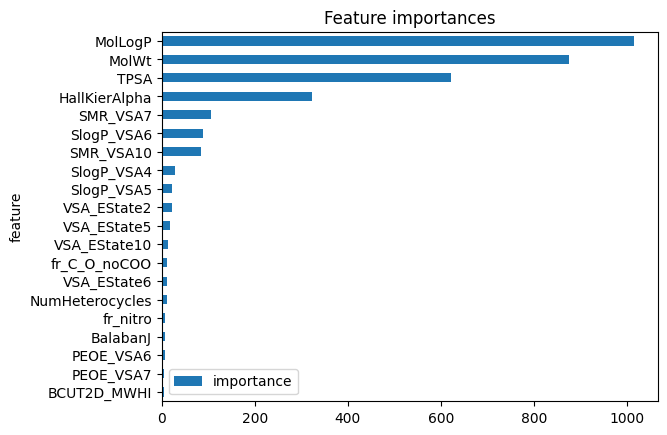

In [35]:
#@title Plotting feature importance
%matplotlib inline

import matplotlib.pyplot as plt

df_plot = dataframe_permutation_ordered.iloc[:20,:].sort_values('importance',ascending=True)

df_plot.plot(
    x="feature",
    kind = "barh",
    stacked = False,
    title = "Feature importances")

Based on this, how many descriptors would you choose to build a model? Use this value in the code below so that we can select them and save them in a `.csv` file. Write the code based on the code developed for classification. If you use the same names, the variable should be `pi_n_feats`.

In [36]:
#@title Select the desired number of descriptors
# Insert the number of features to select here
pi_n_feats = 5

# Get the list of selected descriptor names (top 5 features)
selected_features_pi = dataframe_permutation_ordered['feature'].head(pi_n_feats).tolist()

# Create a subset of the selected descriptors for training
df_train_pi = df_train[['SMILES', 'y'] + selected_features_pi]

# Now take the test DataFrame and select only the descriptor columns of interest
df_test_pi = df_test[['SMILES', 'y'] + selected_features_pi]

# Save both datasets as RAT_LC50_Train_PI_linreg.csv and RAT_LC50_Test_PI_linreg.csv files
df_train_pi.to_csv(PATH + 'RAT_LC50_Train_PI_linreg.csv', sep=';', index=False)
df_test_pi.to_csv(PATH + 'RAT_LC50_Test_PI_linreg.csv', sep=';', index=False)

print(f"Permutation Importance Linear Regression feature selection completed. Selected features: {selected_features_pi}")
print(f"Train shape: {df_train_pi.shape}, Test shape: {df_test_pi.shape}")

Permutation Importance Linear Regression feature selection completed. Selected features: ['MolLogP', 'MolWt', 'TPSA', 'HallKierAlpha', 'SMR_VSA7']
Train shape: (95, 7), Test shape: (41, 7)


Let us try using a decision tree algorithm, as we did before with RFE.

In [37]:
#@title Select features using PI with a decision tree estimator
# Import the SelectFromModel module from sklearn.feature_selection, the DecisionTreeRegressor
# module from sklearn.tree, and the PermutationImportance module from eli5.sklearn
from sklearn.feature_selection import SelectFromModel
from sklearn.tree import DecisionTreeRegressor
from eli5.sklearn import PermutationImportance
import pandas as pd

# Separate the descriptor array and the output variable
X_train = df_train.iloc[:, 2:]
Y_train = df_train['y']

# Instantiate the estimator using the DecisionTreeRegressor algorithm
estimator = DecisionTreeRegressor(random_state=SEED)

# Fit the estimator using the training data
estimator.fit(X_train, Y_train)

# Instantiate and fit the permutation object
perm = PermutationImportance(estimator, random_state=SEED)
perm.fit(X_train, Y_train)

# Select features that increase accuracy by at least 0.01 and store them in a variable called sel
sel = SelectFromModel(perm, threshold=0.01, prefit=True)

# Use the perm.feature_importances_ attribute to obtain the importance of each descriptor
# Store the features and their importances in a DataFrame
dataframe_permutation_dt = pd.DataFrame({
    'feature': X_train.columns,
    'importance': perm.feature_importances_
})

# Sort them to see which ones are the most important
dataframe_permutation_ordered_dt = dataframe_permutation_dt.sort_values(by='importance', ascending=False).reset_index(drop=True)

# Keep this to verify the result
display(dataframe_permutation_ordered_dt.head(20))
print(f"Number of features selected with importance >= 0.01: {sum(dataframe_permutation_ordered_dt['importance'] >= 0.01)}")

,feature,importance
0,BalabanJ,1.110794
1,SPS,0.386123
2,TPSA,0.225353
3,BCUT2D_MWLOW,0.202413
4,MaxPartialCharge,0.161704
5,PEOE_VSA9,0.123390
6,BCUT2D_MWHI,0.054177
7,qed,0.038723
8,MinAbsEStateIndex,0.037836
9,HallKierAlpha,0.032766


Number of features selected with importance >= 0.01: 12


As above, you can run the next cell to see the feature importances represented in a bar plot.

<Axes: title={'center': 'Feature importances'}, ylabel='feature'>

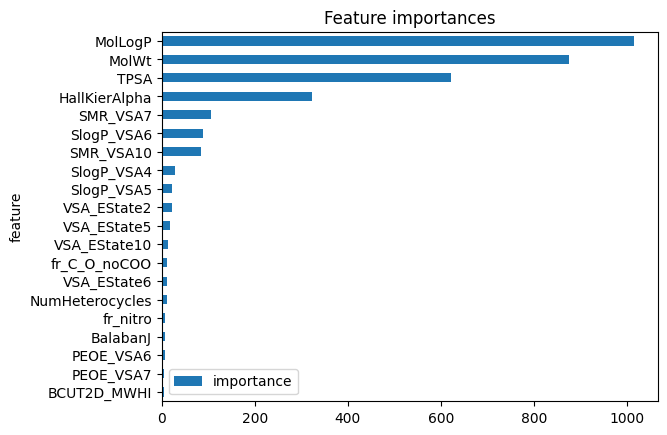

In [38]:
#@title Plotting feature importance
%matplotlib inline

import matplotlib.pyplot as plt

df_plot = dataframe_permutation_ordered.iloc[:20,:].sort_values('importance',ascending=True)

df_plot.plot(
    x="feature",
    kind = "barh",
    stacked = False,
    title = "Feature importances")


Based on this, how many descriptors would you choose to build a model? Enter this value in the `pi_n_feats` variable so that we can select them and save them in a `.csv` file.

In [39]:
#@title Select the desired number of descriptors
# Insert the number of features to select here
pi_n_feats = 5

# Get the list of selected descriptor names (top 5 features)
selected_features_pi_dt = dataframe_permutation_ordered_dt['feature'].head(pi_n_feats).tolist()

# Create a subset of the selected descriptors for training
df_train_pi_dt = df_train[['SMILES', 'y'] + selected_features_pi_dt]

# Now take the test DataFrame and select only the descriptor columns of interest
df_test_pi_dt = df_test[['SMILES', 'y'] + selected_features_pi_dt]

# Save both datasets as RAT_LC50_Train_PI_dectreereg.csv and RAT_LC50_Test_PI_dectreereg.csv files
df_train_pi_dt.to_csv(PATH + 'RAT_LC50_Train_PI_dectreereg.csv', sep=';', index=False)
df_test_pi_dt.to_csv(PATH + 'RAT_LC50_Test_PI_dectreereg.csv', sep=';', index=False)

print(f"Permutation Importance Decision Tree feature selection completed. Selected features: {selected_features_pi_dt}")
print(f"Train shape: {df_train_pi_dt.shape}, Test shape: {df_test_pi_dt.shape}")

Permutation Importance Decision Tree feature selection completed. Selected features: ['BalabanJ', 'SPS', 'TPSA', 'BCUT2D_MWLOW', 'MaxPartialCharge']
Train shape: (95, 7), Test shape: (41, 7)


#### Update the imputation/scaling

It is important to note that, once we have selected a set of features, these are the only ones that should be considered in the model. Therefore, it is useful to reassess the imputation step, because the criterion used to determine which chemicals are more similar, and therefore used to calculate the average, originally included all available descriptors. For this reason, we are going to repeat the imputation and standardisation procedures, but only using the selected features.

The idea is to repeat the imputation and standardisation steps on the datasets that contain only the selected descriptors.

We will write a function to do this automatically for all the DataFrames that contain the selected features. This function will:

- Read the training and test DataFrames with the original descriptor values
- Filter these DataFrames using the columns of the selected descriptors
- Fit the `KNNImputer` with the training DataFrame and transform the training and test DataFrames
- Fit the scaler with the training DataFrame and transform the training and test DataFrames


As you may imagine, we will need the following inputs:

- The original DataFrames
- A file with the filtered columns

In [40]:
#@title Create a function for data imputation and scaling
# Import the required modules
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np

def imputer_scaler(df_target, df_reference, list_descriptors):
    # Instantiate the KNNImputer class, taking into account that the missing values in the previous DataFrame are
    # np.nan, that we want to consider the 3 closest neighbours, and that we want all points in each neighbourhood
    # to be weighted equally
    imputer = KNNImputer(n_neighbors=3, weights='uniform', missing_values=np.nan)

    # Instantiate the scaler
    scaler = StandardScaler()

    # Create a reference DataFrame containing only the list of selected descriptors
    df_reference_filtered = df_reference[list_descriptors]

    # Fit the imputer with the reference DataFrame, create a target DataFrame containing only the selected
    # descriptors, transform the target data, and convert it into a DataFrame
    imputer.fit(df_reference_filtered)
    df_target_filtered = df_target[list_descriptors]
    target_imputed = imputer.transform(df_target_filtered)
    df_target_imputed = pd.DataFrame(target_imputed, columns=list_descriptors, index=df_target.index)

    # Fit the scaler with the imputed DataFrame (fit on reference, transform target)
    # Since we are scaling target using statistics from the reference, let's impute the reference first to fit the scaler
    reference_imputed = imputer.transform(df_reference_filtered)
    scaler.fit(reference_imputed)

    target_scaled = scaler.transform(df_target_imputed)
    df_target_scaled = pd.DataFrame(target_scaled, columns=list_descriptors, index=df_target.index)

    # The imputation only works with the descriptor columns, so we need to concatenate them with the SMILES
    # and y columns from the original DataFrame
    df_imputed_scaled = pd.concat([df_target[['SMILES', 'y']], df_target_scaled], axis=1)

    return df_imputed_scaled

Now that the function has been created, we are going to apply it to the training and test DataFrames generated previously using the different descriptor reduction algorithms.

In [41]:
#@title Apply the function to the training and test DataFrames
import pandas as pd
import os

combinations_algorithms_base_estimators = ['RFE_linreg', 'RFE_dectreereg', 'PI_linreg', 'PI_dectreereg']

# Load original pre-imputation datasets
df_train_orig = pd.read_csv(PATH + 'RAT_LC50_Train.csv', sep=';')
df_test_orig = pd.read_csv(PATH + 'RAT_LC50_Test.csv', sep=';')

# Iterate through the list of estimators
for name in combinations_algorithms_base_estimators:
    # Load the already-generated subset to retrieve its exact list of selected descriptors
    df_subset = pd.read_csv(os.path.join(PATH, f'RAT_LC50_Train_{name}.csv'), sep=';')
    list_descriptors = [col for col in df_subset.columns if col not in ['SMILES', 'y']]

    # Apply the imputer_scaler function to the training subset using itself as the reference
    df_train_cleaned = imputer_scaler(df_train_orig, df_train_orig, list_descriptors)
    df_train_cleaned.to_csv(os.path.join(PATH, f'RAT_LC50_Train_{name}.csv'), sep=';', index=False)

    # Apply the imputer_scaler function to the test subset using training as the reference
    df_test_cleaned = imputer_scaler(df_test_orig, df_train_orig, list_descriptors)
    df_test_cleaned.to_csv(os.path.join(PATH, f'RAT_LC50_Test_{name}.csv'), sep=';', index=False)

print("Imputation and scaling updated successfully for all selected descriptor subsets!")

Imputation and scaling updated successfully for all selected descriptor subsets!


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but Sta

## Part 5: Model development

In [42]:
#@title Data preparation
import pandas as pd
import os

# Select one of the feature reduction algorithms and load the training DataFrame generated with it
selected_subset = 'RFE_linreg'
train_file_path = os.path.join(PATH, f'RAT_LC50_Train_{selected_subset}.csv')
df_train_selected = pd.read_csv(train_file_path, sep=';')

# Split the DataFrame into x (descriptors) and y (response value) variables
# The first two columns are 'SMILES' and 'y', the rest are the selected descriptors
X_train = df_train_selected.iloc[:, 2:]
Y_train = df_train_selected['y']

print(f"Loaded subset: {selected_subset}")
print(f"X_train shape: {X_train.shape}")
print(f"Selected features: {list(X_train.columns)}")

Loaded subset: RFE_linreg
X_train shape: (95, 5)
Selected features: ['BalabanJ', 'PEOE_VSA9', 'TPSA', 'FractionCSP3', 'fr_ether']


In [43]:
#@title Instantiate and configure the estimator
# Import the LinearRegression module from sklearn.linear_model
from sklearn.linear_model import LinearRegression

# Instantiate the LinearRegression estimator
reg_model = LinearRegression()

print("Linear Regression estimator successfully instantiated!")

Linear Regression estimator successfully instantiated!


The last part is to train the model using the data from Step 1. In sklearn, this is done with the fit method, which requires two inputs: the training data and the target values. Check its usage in this [link](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html).

In [44]:
#@title Fit the estimator
# Fit the model with the training data
reg_model.fit(X_train, Y_train)

print("Model training complete!")

Model training complete!


Once an estimator has been fitted, it can be used to predict values. In `sklearn`, this is done using another method of the estimator. Check the [reference](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html) and use it here to predict `X_train`.

Save the predicted values as `Y_train_pred`.

In [45]:
#@title Use the estimator with the training values
# Generate the predicted values for the training dataset
Y_train_pred = reg_model.predict(X_train)

print("Predictions generated successfully!")

Predictions generated successfully!


With the code below, you can visualise how the experimental target values of the training set correlate with the predictions of your model. As we will discuss in more detail in the next module, Validation, evaluating the quality of your model is crucial for the development and assessment of the methods.

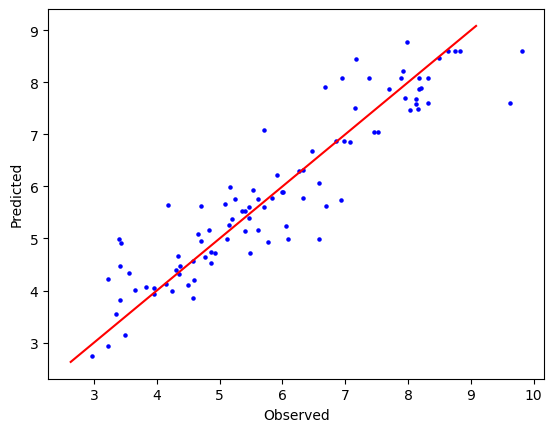

In [46]:
#@title Plotting predicted vs observed values
import matplotlib.pyplot as plt

def regression_plot(y_obs,y_pred):
    fig, ax = plt.subplots(1)
    ax.scatter(y_obs, y_pred, s=5, color="blue", label="original")
    ax.set_xlabel('Observed')
    ax.set_ylabel('Predicted')
    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()
    lims = [max(x0, y0), min(x1, y1)]
    ax.plot(lims, lims, '-r')
    plt.show()

regression_plot(Y_train,Y_train_pred)

The most common way to evaluate the quality of a regression model is to calculate the coefficient of determination ($R^2$) between the predicted and observed values. The formula is:
    
$$R^2 = 1 - \frac{SS_{RES}}{SS_{TOT}} =  1 - \frac{\sum{(y_i - \hat{y}_i)^2}}{\sum{(y_i - \bar{y}_i)^2}}$$

Using the formula above, you can use the `Y_train` and `Y_train_pred` data to calculate the $R^2$ value of your training dataset.


In [47]:
#@title Compute the $R^2$ value
# Import the numpy library
import numpy as np

# Calculate the mean value of the response variable. You can use the mean function from numpy
y_train_mean = np.mean(Y_train)

# Calculate the numerator of the equation, SSRes
ss_res = np.sum((Y_train - Y_train_pred) ** 2)

# Calculate the denominator of the equation, SSTot
ss_tot = np.sum((Y_train - y_train_mean) ** 2)

# Apply the equation to obtain the R2 value
r2_manual = 1 - (ss_res / ss_tot)

print(f"Manually calculated R^2: {r2_manual:.4f}")

Manually calculated R^2: 0.8528


Fortunately, there are functions in `sklearn` and other packages that calculate $R^2$ in a more efficient and simpler way. Use the `sklearn` function `r2_score` to check your function above.

Check the [documentation](https://scikit-learn.org/stable/modules/classes.html#module-sklearn.metrics) for the metrics and find the functions for other common regression metrics, such as explained variance, mean squared error, and mean absolute error.


In [48]:
#@title Compute $R^2$, $EV$, $MSE$ and $MAE$ using the scikit-learn functions
# Import the r2_score, mean_squared_error, mean_absolute_error,
# and explained_variance_score modules from sklearn.metrics
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, explained_variance_score

# Check the documentation for the previously imported modules and compute the four metrics
r2 = r2_score(Y_train, Y_train_pred)
ev = explained_variance_score(Y_train, Y_train_pred)
mse = mean_squared_error(Y_train, Y_train_pred)
mae = mean_absolute_error(Y_train, Y_train_pred)

# Print the four metrics
print(f"R^2: {r2:.4f}")
print(f"Explained Variance: {ev:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")

R^2: 0.8528
Explained Variance: 0.8528
Mean Squared Error (MSE): 0.4161
Mean Absolute Error (MAE): 0.4702


If you want to practise a bit more, you can repeat the model using the descriptors selected by the other feature selection algorithms and compare the metrics.

Which set of descriptors shows the best performance?

Before proceeding, however, you will also want to try different models with different hyperparameters. To check the performance of each model, we are going to provide you with a function similar to the one used in the previous module for the classification problem.

Remember to use the cross-validation values to select the optimal model during the development process.

In [49]:
#@title Function to check regression models

def check_regression_model(model,train_file,test_file,name,save=True):
    from sklearn.model_selection import cross_validate
    from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, explained_variance_score
    # First, open the training and test files and save the DataFrames with the descriptors and endpoint values
    train_dataset = pd.read_csv(train_file,sep=';')
    X_train = train_dataset.iloc[:, 2:]
    Y_train = train_dataset["y"]

    test_dataset = pd.read_csv(test_file,sep=';')
    X_test = test_dataset.iloc[:, 2:]
    Y_test = test_dataset["y"]

    #Fit the model using only the training data
    model.fit(X_train,Y_train)

    #Predict the training data and calculate the metrics
    Y_train_pred = model.predict(X_train)
    tr_R2=round(r2_score(Y_train,Y_train_pred),3)
    tr_mae=round(mean_absolute_error(Y_train,Y_train_pred),3)
    tr_mse=round(mean_squared_error(Y_train,Y_train_pred),3)
    tr_ev=round(explained_variance_score(Y_train,Y_train_pred),3)

    #Predict the test data and calculate the metrics
    Y_test_pred = model.predict(X_test)
    ts_R2=round(r2_score(Y_test,Y_test_pred),3)
    ts_mae=round(mean_absolute_error(Y_test,Y_test_pred),3)
    ts_mse=round(mean_squared_error(Y_test,Y_test_pred),3)
    ts_ev=round(explained_variance_score(Y_test,Y_test_pred),3)

    #Perform cross-validation and save only the test R-square value
    cv_results = cross_validate(model, X_train, Y_train,scoring='r2',return_train_score=True)
    cv_R2_mean=round(cv_results['test_score'].mean(),3)
    cv_R2_dev=round(cv_results['test_score'].std(),3)

    if save:
      results={}
      results.update({name:[tr_R2,tr_mae,tr_mse,tr_ev,
            ts_R2,ts_mae,ts_mse,ts_ev,
            cv_R2_mean,cv_R2_dev]})

    #Print the results
    print('\t\tTRAIN\t\t\t\tTEST')
    print('R squared:\t',tr_R2,'\t\t\t\t',ts_R2)
    print('mae:\t',tr_mae,'\t\t\t\t',ts_mae)
    print('mse:\t',tr_mse,'\t\t\t\t',ts_mse)
    print('ev:\t',tr_ev,'\t\t\t\t',ts_ev)
    print('Cross validation R squared:',cv_R2_mean,'+/-',cv_R2_dev)

    return [tr_R2,tr_mae,tr_mse,tr_ev,
            ts_R2,ts_mae,ts_mse,ts_ev,
            cv_R2_mean,cv_R2_dev]






Now, you can try different algorithms and hyperparameters. Then, once you have selected the best one, you can proceed to validate it.

## Part 6: Validation

While the quality of the model on the training set is a measure of the quality of the fit, the objective of a QSAR model is to predict values for unknown molecules outside the dataset. Therefore, we need to predict the values for the test dataset and evaluate them.

First, we are going to recover the regression plot function that we saw in the previous notebook.

In [50]:
#@title Defining a function to generate a regression plot
import matplotlib.pyplot as plt

def regression_plot(y_obs,y_pred):
    fig, ax = plt.subplots(1)
    ax.scatter(y_obs, y_pred, s=5, color="blue", label="original")
    ax.set_xlabel('Observed')
    ax.set_ylabel('Predicted')
    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()
    lims = [max(x0, y0), min(x1, y1)]
    ax.plot(lims, lims, '-r')
    plt.show()

Before validating the model, and because we are in a new notebook, we need to generate it again.

We are going to do this using the linear regression algorithm again.

In [51]:
#@title Generate a predictive model
import pandas as pd
from sklearn.linear_model import LinearRegression

# Select one of the feature reduction algorithms and load the training DataFrame generated with it
selected_subset = 'RFE_linreg'
train_file_path = PATH + f'RAT_LC50_Train_{selected_subset}.csv'
df_train_selected = pd.read_csv(train_file_path, sep=';')

# Split the DataFrame into x (descriptors) and y (response value) variables
X_train = df_train_selected.iloc[:, 2:]
Y_train = df_train_selected['y']

# Instantiate the LinearRegression estimator and fit the model with the training data
reg_model = LinearRegression()
reg_model.fit(X_train, Y_train)

print("Model regenerated and trained successfully!")

Model regenerated and trained successfully!


Now that the model has been generated again, we are going to predict the response values of the test set and observe the predictive power of the model.

Test Set R^2 Score: 0.7107


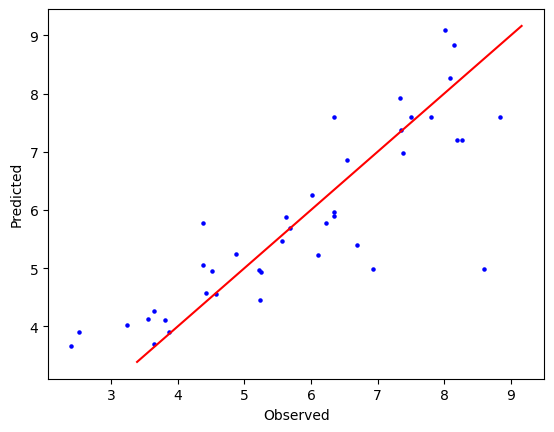

In [52]:
#@title Predict the response value of the test set
from sklearn.metrics import r2_score
import pandas as pd

# Load the corresponding DataFrame with the test set from the same feature reduction algorithm
test_file_path = PATH + f'RAT_LC50_Test_{selected_subset}.csv'
df_test_selected = pd.read_csv(test_file_path, sep=';')

# Split the test DataFrame into x (descriptors) and y (response value) variables
X_test = df_test_selected.iloc[:, 2:]
Y_test = df_test_selected['y']

# Predict the test response values and store them in the Y_test_pred variable
Y_test_pred = reg_model.predict(X_test)

# Use the regression_plot and r2_score functions to visualise how good the model is
r2_test = r2_score(Y_test, Y_test_pred)
print(f"Test Set R^2 Score: {r2_test:.4f}")

regression_plot(Y_test, Y_test_pred)

The regression plot and the $R^2$ value obtained show that the model is not good and that we need to find ways to improve its predictive power. This can be done by changing the hyperparameters of the selected algorithm, or by changing the algorithm directly.

The algorithms used to train the model can be tuned by adjusting their hyperparameters. Which parameters can be used depends strongly on the nature of the algorithm. In the case of linear regression, there are few parameters to fit.

One of these parameters is a logical variable that determines whether the intercept is calculated or assumed to be 0. Check the documentation to find the keyword for this parameter and the default value, `True` or `False`, that was used in our previous model. Repeat the model below by manually setting the hyperparameter to the non-default value.

Does it fit better or worse?

Training Set R^2 Score (no intercept): -11.4072


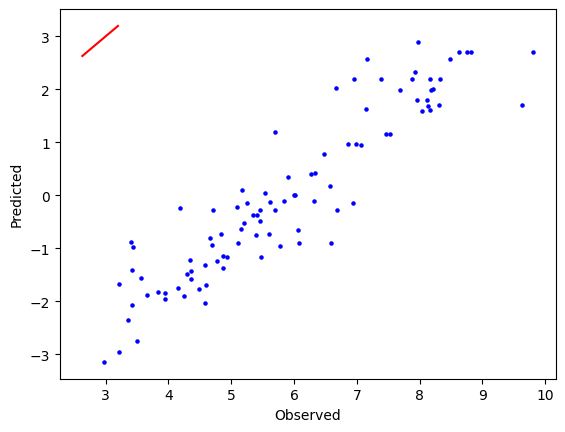

In [53]:
#@title Modification of hyperparameters for the linear regression algorithm
# Import the necessary libraries
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import pandas as pd

# Instantiate the LinearRegression estimator setting fit_intercept to False
reg_model_no_intercept = LinearRegression(fit_intercept=False)

# Load the training DataFrame again and split it into x (descriptors) and y (response value) variables
train_file_path = PATH + f'RAT_LC50_Train_{selected_subset}.csv'
df_train_selected = pd.read_csv(train_file_path, sep=';')
X_train = df_train_selected.iloc[:, 2:]
Y_train = df_train_selected['y']

# Fit the model with the training data and predict the response values of the training data
reg_model_no_intercept.fit(X_train, Y_train)
Y_train_pred_no_intercept = reg_model_no_intercept.predict(X_train)

# Use the plot and r2 score to evaluate the model
r2_train_no_intercept = r2_score(Y_train, Y_train_pred_no_intercept)
print(f"Training Set R^2 Score (no intercept): {r2_train_no_intercept:.4f}")

regression_plot(Y_train, Y_train_pred_no_intercept)

Now you have to repeat the same procedure by yourself, but with a different algorithm: the support vector machine regressor. You can find more information about this algorithm in this [link](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVR.html).


Use the same data as in Example 1 to train a support vector regressor algorithm. Also predict the training data and plot your results.

Training Set R^2 Score (SVR): 0.8968


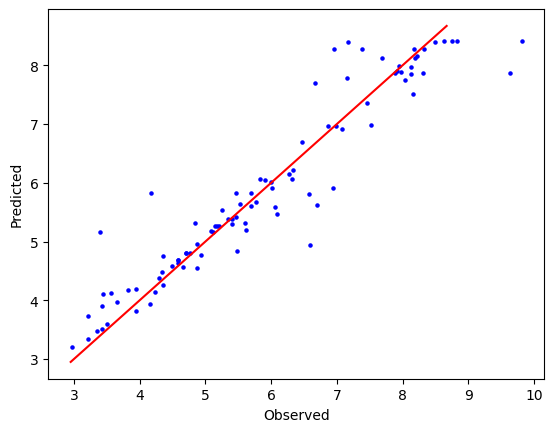

In [54]:
#@title Using another algorithm: Support Vector Machine Regressor
# Import the SVR module from sklearn.svm
from sklearn.svm import SVR
from sklearn.metrics import r2_score
import pandas as pd

# Load the training DataFrame and split it into x (descriptors) and y (response value) variables
train_file_path = PATH + f'RAT_LC50_Train_{selected_subset}.csv'
df_train_selected = pd.read_csv(train_file_path, sep=';')
X_train = df_train_selected.iloc[:, 2:]
Y_train = df_train_selected['y']

# Instantiate the SVR estimator, fit the model with the training data, and predict the response values of the training data
svr_model = SVR()
svr_model.fit(X_train, Y_train)
Y_train_pred_svr = svr_model.predict(X_train)

# Use the plot and r2 score to evaluate the model
r2_train_svr = r2_score(Y_train, Y_train_pred_svr)
print(f"Training Set R^2 Score (SVR): {r2_train_svr:.4f}")

regression_plot(Y_train, Y_train_pred_svr)

In the case of the support vector machine, one of the most important hyperparameters is `c`. Repeat the model, adjusting this value to 10.

Training Set R^2 Score (SVR with C=10): 0.9210


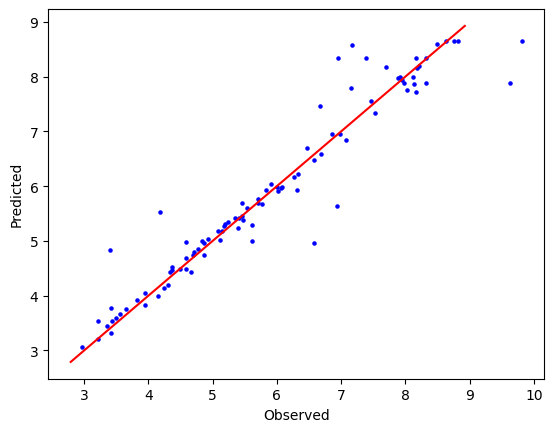

In [55]:
#@title Modification of hyperparameters for the SVR algorithm
from sklearn.svm import SVR
from sklearn.metrics import r2_score
import pandas as pd

# Load the training DataFrame and split it into x (descriptors) and y (response value) variables
train_file_path = PATH + f'RAT_LC50_Train_{selected_subset}.csv'
df_train_selected = pd.read_csv(train_file_path, sep=';')
X_train = df_train_selected.iloc[:, 2:]
Y_train = df_train_selected['y']

# Instantiate the SVR estimator with the C hyperparameter set to 10, fit the model with
# the training data, and predict the response values of the training data
svr_model_c10 = SVR(C=10)
svr_model_c10.fit(X_train, Y_train)
Y_train_pred_svr_c10 = svr_model_c10.predict(X_train)

# Use the plot and r2 score to evaluate the model
r2_train_svr_c10 = r2_score(Y_train, Y_train_pred_svr_c10)
print(f"Training Set R^2 Score (SVR with C=10): {r2_train_svr_c10:.4f}")

regression_plot(Y_train, Y_train_pred_svr_c10)

Another example of a machine learning algorithm is neural networks. Scikit-learn also includes a few neural-network-based algorithms.

Use the multi-layer perceptron regressor, which you can find in the scikit-learn [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPRegressor.html)) to fit your data.


Training Set R^2 Score (MLP): 0.8879


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


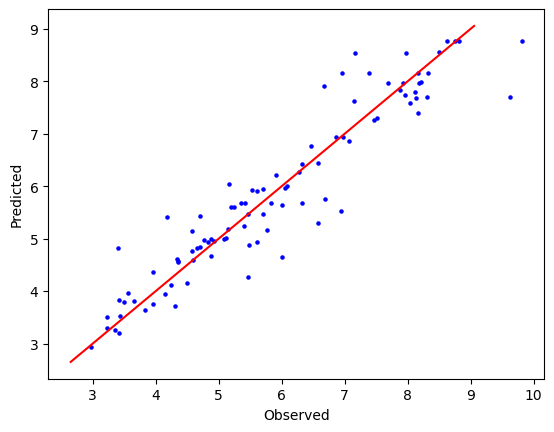

In [56]:
#@title Using another algorithm: Neural Networks
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import r2_score
import pandas as pd

# Load the training DataFrame and split it into x (descriptors) and y (response value) variables
train_file_path = PATH + f'RAT_LC50_Train_{selected_subset}.csv'
df_train_selected = pd.read_csv(train_file_path, sep=';')
X_train = df_train_selected.iloc[:, 2:]
Y_train = df_train_selected['y']

# Instantiate the MLPRegressor estimator with a fixed random state for reproducibility,
# fit the model with the training data, and predict the response values of the training data
mlp_model = MLPRegressor(random_state=SEED, max_iter=1000)
mlp_model.fit(X_train, Y_train)
Y_train_pred_mlp = mlp_model.predict(X_train)

# Use the plot and r2 score to evaluate the model
r2_train_mlp = r2_score(Y_train, Y_train_pred_mlp)
print(f"Training Set R^2 Score (MLP): {r2_train_mlp:.4f}")

regression_plot(Y_train, Y_train_pred_mlp)

Now, you should review the scikit-learn documentation and find the extra-trees algorithm, then retrain the model. The extra-trees algorithm is an ensemble method that fits several different decision trees and uses their average to improve its predictive ability. Check the [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.ExtraTreesRegressor.html) and build your model using 40 trees in the forest.

Training Set R^2 Score (Extra-Trees): 0.9871


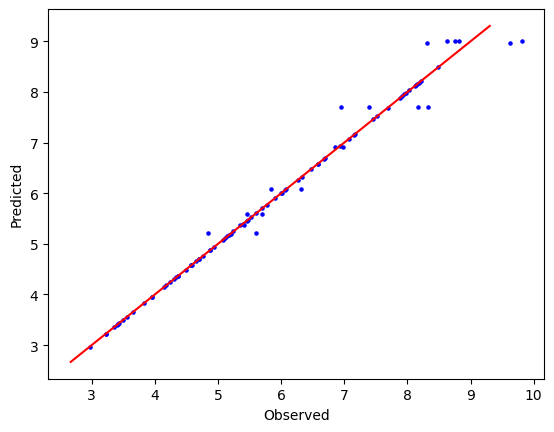

In [57]:
#@title Using another algorithm: Extra-Trees Regressor
# Import the ExtraTreesRegressor module from sklearn.ensemble
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import r2_score
import pandas as pd

# Load the training DataFrame and split it into x (descriptors) and y (response value) variables
train_file_path = PATH + f'RAT_LC50_Train_{selected_subset}.csv'
df_train_selected = pd.read_csv(train_file_path, sep=';')
X_train = df_train_selected.iloc[:, 2:]
Y_train = df_train_selected['y']

# Instantiate the ExtraTreesRegressor estimator with 40 trees in the forest, fit the model with
# the training data, and predict the response values of the training data
et_model = ExtraTreesRegressor(n_estimators=40, random_state=SEED)
et_model.fit(X_train, Y_train)
Y_train_pred_et = et_model.predict(X_train)

# Use the plot and r2 score to evaluate the model
r2_train_et = r2_score(Y_train, Y_train_pred_et)
print(f"Training Set R^2 Score (Extra-Trees): {r2_train_et:.4f}")

regression_plot(Y_train, Y_train_pred_et)

### TASK: Adjusting hyperparameters

As seen before, adjusting the hyperparameters of a method can dramatically affect its fitting ability. In this task, we are going to evaluate the effect of changing one hyperparameter on both the quality of the training fit and the predictive ability on the test set.

Write code that repeats the model for RAT LC₅₀ inhalation using SVR, but changing the value of the `c` parameter from 1 to 50. You should save the results in three lists: `c_values` with the values of `c`, `rsqs_train` with the training $R^2$ values, and `rsqs_test` with the test $R^2$ values, for proper visualisation of the results.

In [58]:
#@title Adjusting hyperparameters
# Import the SVR module and necessary libraries
from sklearn.svm import SVR
from sklearn.metrics import r2_score
import pandas as pd
import seaborn as sns

# Load the training and test DataFrames and split them into x (descriptors)
# and y (response value) variables, as X_train, Y_train, X_test, and Y_test
train_file_path = PATH + f'RAT_LC50_Train_{selected_subset}.csv'
test_file_path = PATH + f'RAT_LC50_Test_{selected_subset}.csv'

df_train_selected = pd.read_csv(train_file_path, sep=';')
df_test_selected = pd.read_csv(test_file_path, sep=';')

X_train = df_train_selected.iloc[:, 2:]
Y_train = df_train_selected['y']

X_test = df_test_selected.iloc[:, 2:]
Y_test = df_test_selected['y']

# Create three empty lists to store the C values, the R squares values for the training set predictions, and the
# R squares values for the test set predictions, as c_values, rsqs_train, and rsqs_test
c_values = []
rsqs_train = []
rsqs_test = []

# Iterate through a range of C values from 1 to 50
for c in range(1, 51):
    # For each C value, instantiate the SVR estimator with the corresponding C value
    svr_temp = SVR(C=c)

    # Fit the model with the training data and then predict the response values for both the training and test sets
    svr_temp.fit(X_train, Y_train)
    Y_train_pred_temp = svr_temp.predict(X_train)
    Y_test_pred_temp = svr_temp.predict(X_test)

    # Use the r2_score function to compute the r2 score value for the prediction
    # of the response value in both the training and test sets
    r2_tr = r2_score(Y_train, Y_train_pred_temp)
    r2_ts = r2_score(Y_test, Y_test_pred_temp)

    # Append the C value, the training r2 score value, and the test r2 score value to their respective lists
    c_values.append(c)
    rsqs_train.append(r2_tr)
    rsqs_test.append(r2_ts)

print("Hyperparameter search completed. Lists populated successfully!")

Hyperparameter search completed. Lists populated successfully!


Now, with the following lines, the generated lists containing the C values and the $R^2$ values will be printed on screen and displayed in a line plot.

From these results, we can decide what the optimal C value is for our problem.

C 	R2-train	R2-test
1	 0.897		 0.672
2	 0.908		 0.667
3	 0.914		 0.655
4	 0.916		 0.648
5	 0.917		 0.644
6	 0.918		 0.643
7	 0.919		 0.646
8	 0.920		 0.649
9	 0.920		 0.648
10	 0.921		 0.646
11	 0.922		 0.645
12	 0.922		 0.644
13	 0.923		 0.643
14	 0.923		 0.642
15	 0.923		 0.642
16	 0.924		 0.641
17	 0.924		 0.640
18	 0.924		 0.639
19	 0.924		 0.638
20	 0.924		 0.638
21	 0.924		 0.637
22	 0.924		 0.637
23	 0.924		 0.637
24	 0.924		 0.638
25	 0.925		 0.638
26	 0.925		 0.637
27	 0.925		 0.637
28	 0.925		 0.637
29	 0.925		 0.636
30	 0.925		 0.636
31	 0.925		 0.636
32	 0.925		 0.635
33	 0.925		 0.635
34	 0.925		 0.635
35	 0.925		 0.634
36	 0.925		 0.634
37	 0.925		 0.633
38	 0.925		 0.633
39	 0.925		 0.633
40	 0.925		 0.633
41	 0.925		 0.633
42	 0.926		 0.633
43	 0.926		 0.634
44	 0.926		 0.634
45	 0.926		 0.634
46	 0.926		 0.634
47	 0.926		 0.634
48	 0.926		 0.634
49	 0.926		 0.634
50	 0.926		 0.634


<Axes: xlabel='C'>

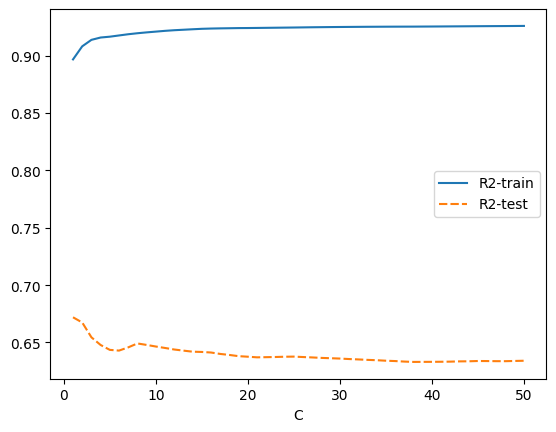

In [59]:
#@title Printing the results
print("C \tR2-train\tR2-test")
for ind, val in enumerate(c_values):
    print("{}\t{:6.3f}\t\t{:6.3f}".format(val,rsqs_train[ind],rsqs_test[ind]))

res_df = pd.DataFrame({'C':c_values,'R2-train':rsqs_train,"R2-test":rsqs_test}).set_index('C')



sns.lineplot(data=res_df)

### TASK: Evaluate and tune the hyperparameters of the SVR model
Review the scikit-learn documentation and choose an SVR regression algorithm to use with your data. Build a model based on the same data as above, changing the hyperparameter `c` according to the best result from the previous task, and plot the predictions for the training and test data.  


Optimal SVR (C=1) Training Set R^2 Score: 0.8968
Optimal SVR (C=1) Test Set R^2 Score:     0.6720

--- Training Set Predictions vs Observed ---


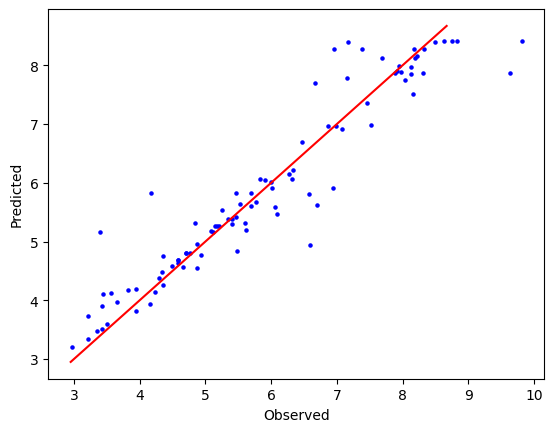

--- Test Set Predictions vs Observed ---


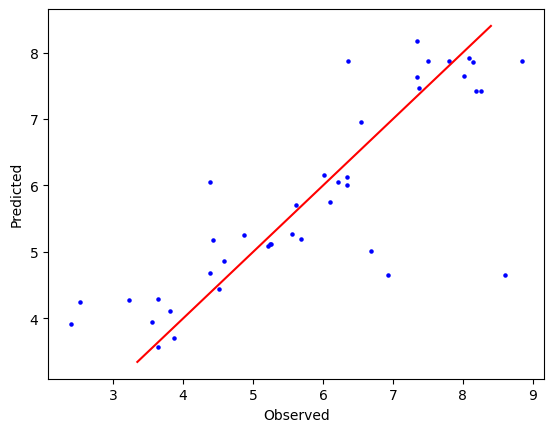

In [60]:
#@title Evaluate and check the hyperparameters for the SVR model
from sklearn.svm import SVR
from sklearn.metrics import r2_score
import pandas as pd
import matplotlib.pyplot as plt

# Load the training and test DataFrames
train_file_path = PATH + f'RAT_LC50_Train_{selected_subset}.csv'
test_file_path = PATH + f'RAT_LC50_Test_{selected_subset}.csv'

df_train_selected = pd.read_csv(train_file_path, sep=';')
df_test_selected = pd.read_csv(test_file_path, sep=';')

X_train = df_train_selected.iloc[:, 2:]
Y_train = df_train_selected['y']

X_test = df_test_selected.iloc[:, 2:]
Y_test = df_test_selected['y']

# Instantiate the SVR estimator with the optimal C hyperparameter (C = 1)
optimal_svr = SVR(C=1)

# Fit the model with the training data
optimal_svr.fit(X_train, Y_train)

# Predict the response values for both sets
Y_train_pred_opt = optimal_svr.predict(X_train)
Y_test_pred_opt = optimal_svr.predict(X_test)

# Compute and display R^2 scores
r2_train_opt = r2_score(Y_train, Y_train_pred_opt)
r2_test_opt = r2_score(Y_test, Y_test_pred_opt)

print(f"Optimal SVR (C=1) Training Set R^2 Score: {r2_train_opt:.4f}")
print(f"Optimal SVR (C=1) Test Set R^2 Score:     {r2_test_opt:.4f}")

# Generate regression plots for visualization
print("\n--- Training Set Predictions vs Observed ---")
regression_plot(Y_train, Y_train_pred_opt)

print("--- Test Set Predictions vs Observed ---")
regression_plot(Y_test, Y_test_pred_opt)